In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb


In [ ]:
from sklea

In [2]:
# Employee Attrition Analyzer
# Name: Shumaila Shaikh
# Roll No: 24f_Ai _093

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [4]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

In [6]:
# Load the dataset

df = pd.read_csv("/content/ employee.csv")

# Display first 5 rows
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
df.describe()

Dataset Shape: (1470, 35)

Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel   

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [9]:
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [10]:
# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [11]:
# Remove duplicate rows
df = df.drop_duplicates()


In [12]:
# Remove columns that contain only one unique value
constant_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

In [13]:
print("Constant Columns:", constant_cols)

df = df.drop(columns=constant_cols)

print("Cleaned Dataset Shape:", df.shape)

Constant Columns: ['EmployeeCount', 'Over18', 'StandardHours']
Cleaned Dataset Shape: (1470, 32)


Attrition
No     1233
Yes     237
Name: count, dtype: int64


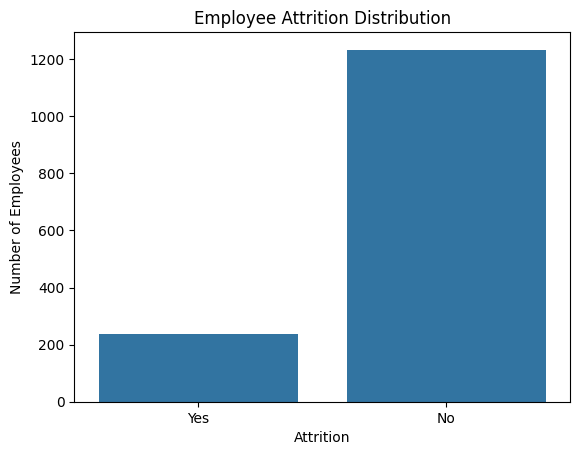

In [14]:
# Target distribution

print(df["Attrition"].value_counts())

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

In [15]:
attrition_percentage = (
    df["Attrition"].value_counts(normalize=True) * 100
)

print(attrition_percentage)

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


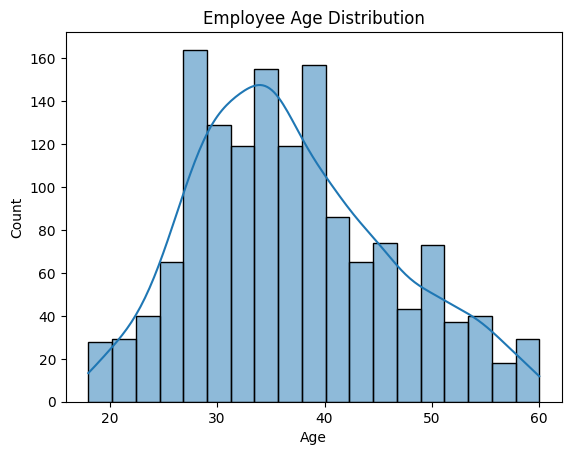

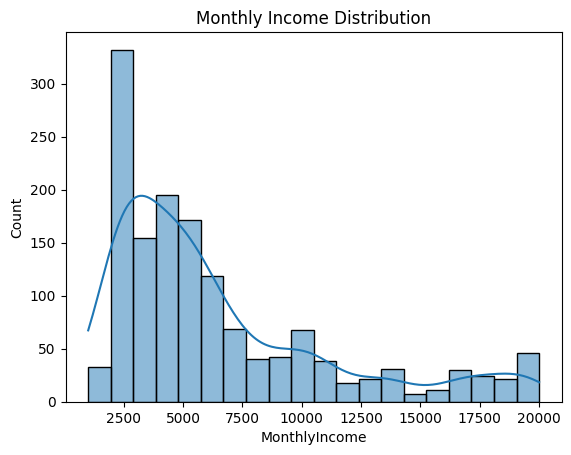

In [16]:
# Age distribution

sns.histplot(data=df, x="Age", kde=True)

plt.title("Employee Age Distribution")
plt.show()


# Monthly income distribution

sns.histplot(data=df, x="MonthlyIncome", kde=True)

plt.title("Monthly Income Distribution")
plt.show()

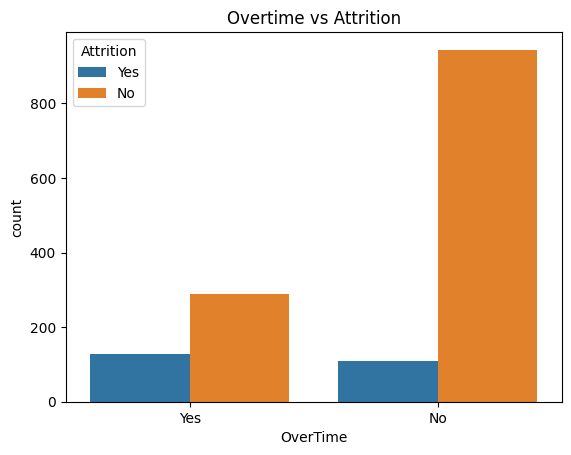

In [17]:
# Checking overtime and attrition

sns.countplot(
    data=df,
    x="OverTime",
    hue="Attrition"
)

plt.title("Overtime vs Attrition")

plt.show()

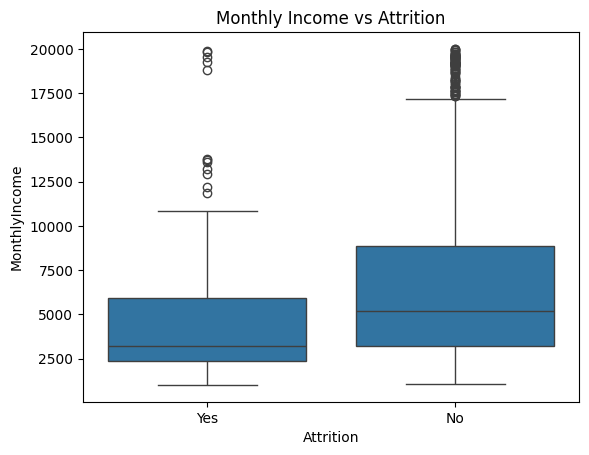

In [19]:
# Checking monthly income and attrition

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income vs Attrition")

plt.show()

In [20]:
# Converting Attrition into numerical values

df["Attrition"] = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

# Checking result

df["Attrition"].value_counts()

,count
Attrition,
0,1233
1,237


In [21]:
# Separating target variable

y = df["Attrition"]

# Removing target column from input data

X = df.drop("Attrition", axis=1)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (1470, 31)
Target Shape: (1470,)


In [22]:
# Finding numerical columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Finding categorical columns

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical Columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [23]:
# Splitting data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1176, 31)
Testing Data: (294, 31)


In [24]:
# Preprocessing numerical data

numerical_process = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler())
])

In [25]:
# Preprocessing categorical data

categorical_process = Pipeline([

    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),

    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

In [26]:
# Combining numerical and categorical preprocessing

preprocessor = ColumnTransformer([

    ("numerical",
     numerical_process,
     numerical_columns),

    ("categorical",
     categorical_process,
     categorical_columns)
])

In [27]:
# Creating Logistic Regression model

logistic_model = Pipeline([

    ("preprocessing", preprocessor),

    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Training the model

logistic_model.fit(
    X_train,
    y_train
)

# Making predictions

logistic_pred = logistic_model.predict(X_test)

print("Logistic Regression completed!")

Logistic Regression completed!


In [28]:
# Calculating F1 score

logistic_f1 = f1_score(
    y_test,
    logistic_pred
)

print("Logistic Regression F1 Score:",
      logistic_f1)

Logistic Regression F1 Score: 0.4444444444444444


In [29]:
# Creating Decision Tree model

tree_model = Pipeline([

    ("preprocessing", preprocessor),

    ("model", DecisionTreeClassifier(
        max_depth=6,
        random_state=42,
        class_weight="balanced"
    ))
])


In [30]:
# Training the model

tree_model.fit(
    X_train,
    y_train
)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EmployeeNumber',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyIncome',
                                                   'MonthlyRate'...
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=6,
                                        random_state=42))])

In [31]:
# Making predictions

tree_pred = tree_model.predict(X_test)

print("Decision Tree completed!")

Decision Tree completed!


In [32]:
# Calculating F1 score

tree_f1 = f1_score(
    y_test,
    tree_pred
)

print("Decision Tree F1 Score:",
      tree_f1)

Decision Tree F1 Score: 0.43333333333333335


In [34]:
# Creating Random Forest model

forest_model = Pipeline([

    ("preprocessing", preprocessor),

    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

In [35]:
# Training the model

forest_model.fit(
    X_train,
    y_train
)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EmployeeNumber',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyIncome',
                                                   'MonthlyRate'...
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

In [36]:
# Making predictions

forest_pred = forest_model.predict(X_test)

print("Random Forest completed!")

Random Forest completed!


In [37]:
# Calculating F1 score

forest_f1 = f1_score(
    y_test,
    forest_pred
)

print("Random Forest F1 Score:",
      forest_f1)

Random Forest F1 Score: 0.21052631578947367


In [38]:
# Comparing the F1 scores of all three models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "F1 Score": [
        logistic_f1,
        tree_f1,
        forest_f1
    ]
})

results

,Model,F1 Score
0,Logistic Regression,0.444444
1,Decision Tree,0.433333
2,Random Forest,0.210526


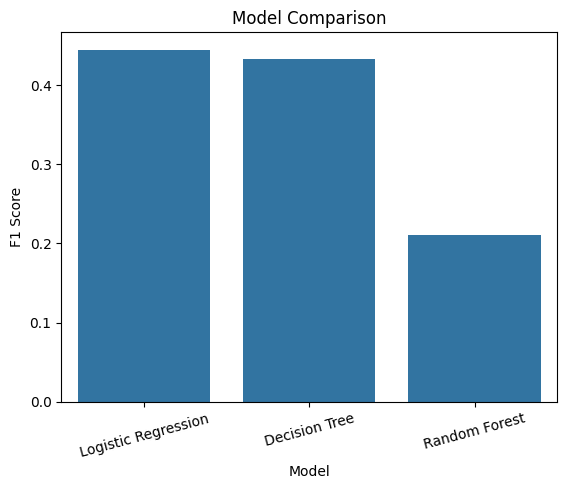

In [39]:
# Comparing models using a bar graph

sns.barplot(
    data=results,
    x="Model",
    y="F1 Score"
)

plt.title("Model Comparison")
plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.xticks(rotation=15)

plt.show()

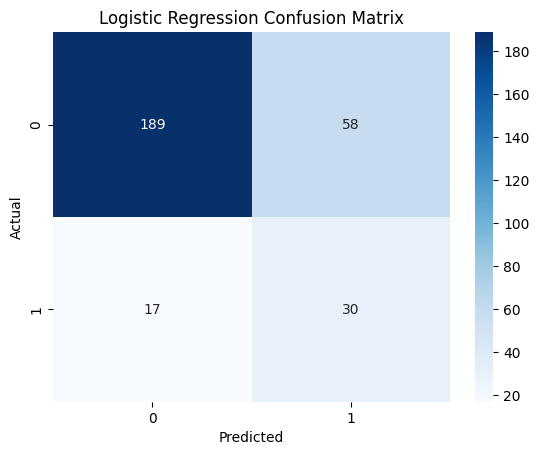

In [40]:
# Confusion matrix for Logistic Regression

cm_logistic = confusion_matrix(
    y_test,
    logistic_pred
)

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

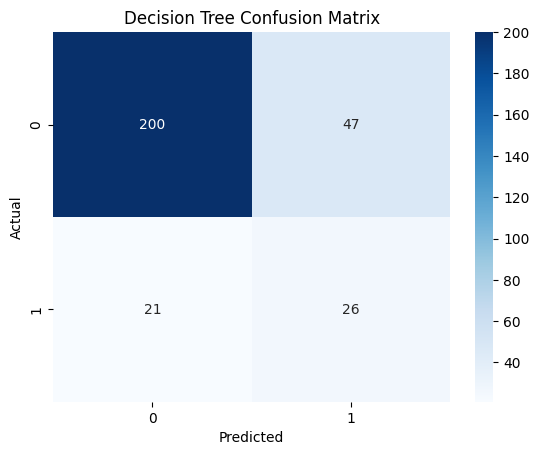

In [42]:
# Confusion matrix for Decision Tree

cm_tree = confusion_matrix(
    y_test,
    tree_pred
)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

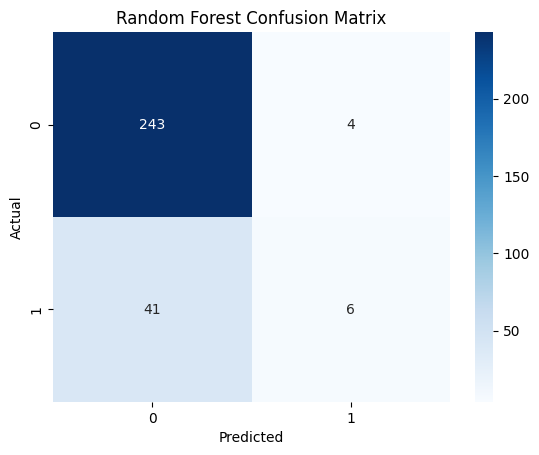

In [43]:
# Confusion matrix for Random Forest

cm_forest = confusion_matrix(
    y_test,
    forest_pred
)

sns.heatmap(
    cm_forest,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [44]:
# Classification report for Logistic Regression

print("Logistic Regression")
print(
    classification_report(
        y_test,
        logistic_pred
    )
)

Logistic Regression
              precision    recall  f1-score   support

           0       0.92      0.77      0.83       247
           1       0.34      0.64      0.44        47

    accuracy                           0.74       294
   macro avg       0.63      0.70      0.64       294
weighted avg       0.83      0.74      0.77       294



In [45]:
# Classification report for Decision Tree

print("Decision Tree")
print(
    classification_report(
        y_test,
        tree_pred
    )
)

Decision Tree
              precision    recall  f1-score   support

           0       0.90      0.81      0.85       247
           1       0.36      0.55      0.43        47

    accuracy                           0.77       294
   macro avg       0.63      0.68      0.64       294
weighted avg       0.82      0.77      0.79       294



In [46]:
# Classification report for Random Forest

print("Random Forest")
print(
    classification_report(
        y_test,
        forest_pred
    )
)

Random Forest
              precision    recall  f1-score   support

           0       0.86      0.98      0.92       247
           1       0.60      0.13      0.21        47

    accuracy                           0.85       294
   macro avg       0.73      0.56      0.56       294
weighted avg       0.81      0.85      0.80       294



In [47]:
# Getting the trained Random Forest model

random_forest = forest_model.named_steps["model"]

In [48]:
# Getting feature names after preprocessing

feature_names = forest_model.named_steps[
    "preprocessing"
].get_feature_names_out()

In [49]:
# Getting importance of each feature

importance_values = random_forest.feature_importances_

In [50]:
# Creating a table of feature importance

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sorting features from highest to lowest

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
10,numerical__MonthlyIncome,0.061737
0,numerical__Age,0.061362
1,numerical__DailyRate,0.048941
17,numerical__TotalWorkingYears,0.048784
20,numerical__YearsAtCompany,0.046423
23,numerical__YearsWithCurrManager,0.041260
4,numerical__EmployeeNumber,0.040862
6,numerical__HourlyRate,0.040728
11,numerical__MonthlyRate,0.040724
2,numerical__DistanceFromHome,0.038131


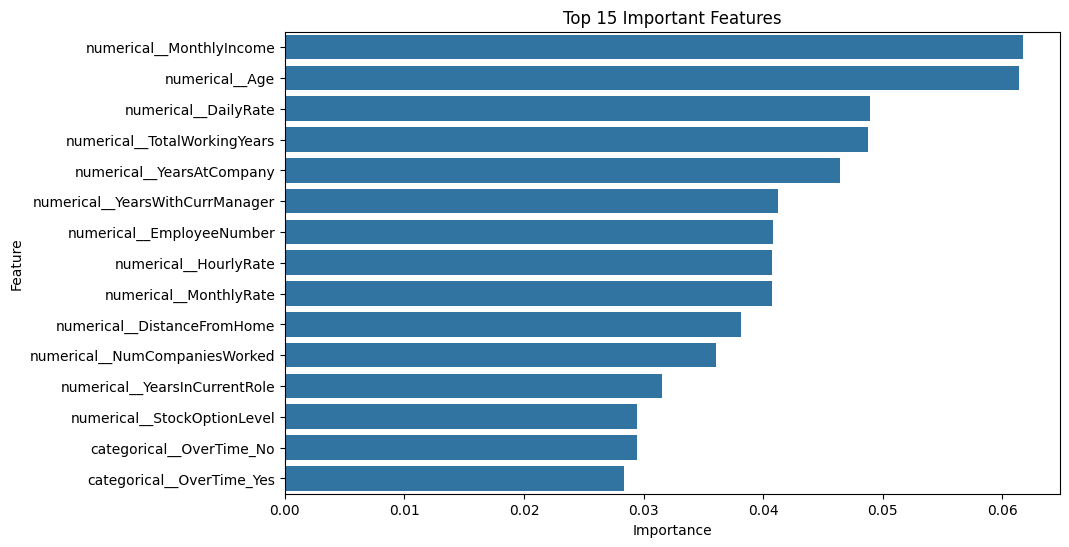

In [51]:
# Showing top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [53]:
# Final comparison of all models

final_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, forest_pred)
    ],

    "Precision": [
        precision_score(y_test, logistic_pred),
        precision_score(y_test, tree_pred),
        precision_score(y_test, forest_pred)
    ],

    "Recall": [
        recall_score(y_test, logistic_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, forest_pred)
    ],

    "F1 Score": [
        f1_score(y_test, logistic_pred),
        f1_score(y_test, tree_pred),
        f1_score(y_test, forest_pred)
    ]
})

final_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.744898,0.340909,0.638298,0.444444
1,Decision Tree,0.768707,0.356164,0.553191,0.433333
2,Random Forest,0.846939,0.600000,0.127660,0.210526


In [54]:
# Finding the model with the highest F1 Score

best_model = final_results.loc[
    final_results["F1 Score"].idxmax()
]

print(best_model)

Model        Logistic Regression
Accuracy                0.744898
Precision               0.340909
Recall                  0.638298
F1 Score                0.444444
Name: 0, dtype: object
